# MAKİNE ÖĞRENMESİ DERSİ PROJE ÖDEVİ

**Proje Konusu:** İkinci El Araç Fiyat Tahmini (Regresyon Problemi)
**Grup Üyeleri:** [Buraya İsimleri Ekleyin]
**Ders:** Makine Öğrenmesi

---

## 0. Kütüphanelerin Yüklenmesi ve Veri Setinin Okunması

In [1]:
# Gerekli Kütüphaneler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Makine Öğrenmesi Kütüphaneleri
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Modeller
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# XAI (Açıklanabilir Yapay Zeka)
# !pip install shap  # Eğer yüklü değilse bu satırı çalıştırın
import shap

# Uyarıları kapatma
import warnings
warnings.filterwarnings('ignore')

# Veri Setinin Okunması
# Not: 'cleaned_used_cars.csv' dosyasının bu notebook ile aynı klasörde olduğundan emin olun.
df = pd.read_csv('cleaned_used_cars.csv')

print("Veri Seti Boyutu:", df.shape)
display(df.head())

# Hedef değişken 'price' olduğu için, fiyatı boş olan satırları baştan temizleyelim
df = df.dropna(subset=['price'])

Veri Seti Boyutu: (4009, 12)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,clean_title,price,accident_binary
0,Ford,Utility Police Interceptor Base,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,1,10300,1
1,Hyundai,Palisade SEL,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,1,38005,1
2,Lexus,RX 350 RX 350,2022,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,0,54598,0
3,INFINITI,Q50 Hybrid Sport,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,1,15500,0
4,Audi,Q3 45 S line Premium Plus,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,0,34999,0


## 1. Veri Ön İşleme (Preprocessing)

In [2]:
# 1.1. Tutarsız Verilerin Temizlenmesi
df.replace(['–', '—', 'nan', 'None'], np.nan, inplace=True)

# 1.2. Feature Engineering: Engine sütunundan HP ve Litre bilgisini çekme
def extract_hp(text):
    if pd.isna(text): return np.nan
    match = re.search(r'(\d+\.?\d*)HP', str(text))
    return float(match.group(1)) if match else np.nan

def extract_liters(text):
    if pd.isna(text): return np.nan
    match = re.search(r'(\d+\.?\d*)L', str(text))
    return float(match.group(1)) if match else np.nan

df['horsepower'] = df['engine'].apply(extract_hp)
df['engine_liters'] = df['engine'].apply(extract_liters)

# Gereksiz sütunların kaldırılması
drop_cols = ['engine'] 
df.drop(columns=drop_cols, inplace=True)

# 1.3. Eksik Verilerin Doldurulması
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

# Sayısal verileri medyan, kategorik verileri mod ile doldurma
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    if len(df[col].mode()) > 0:
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna('Unknown')

# 1.4. Aykırı Değer Temizliği (IQR Yöntemi ile Fiyat Temizliği)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_cleaned = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Temizlik sonrası veri boyutu: {df_cleaned.shape}")

# CSV Kaydı
df_cleaned.to_csv('1_data_cleaned_engineered.csv', index=False)

Temizlik sonrası veri boyutu: (3765, 13)


## 2. Veri Analizi ve Görselleştirme (EDA)

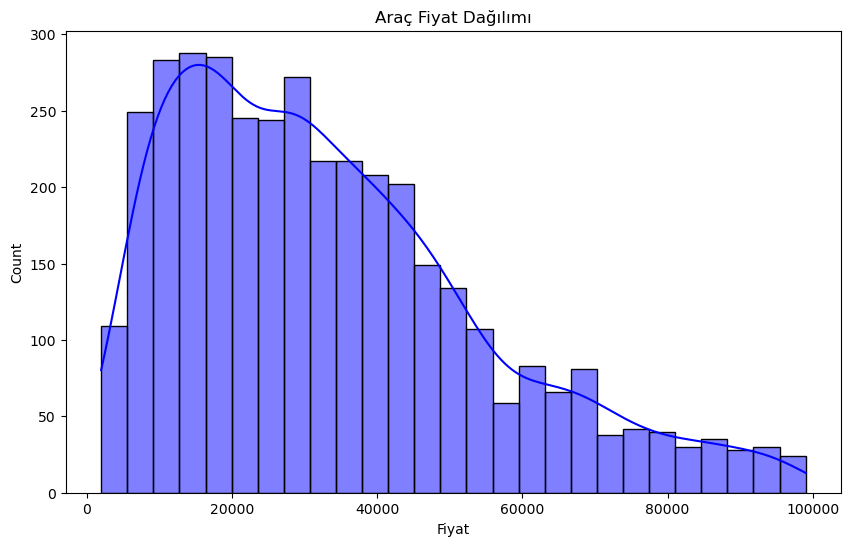

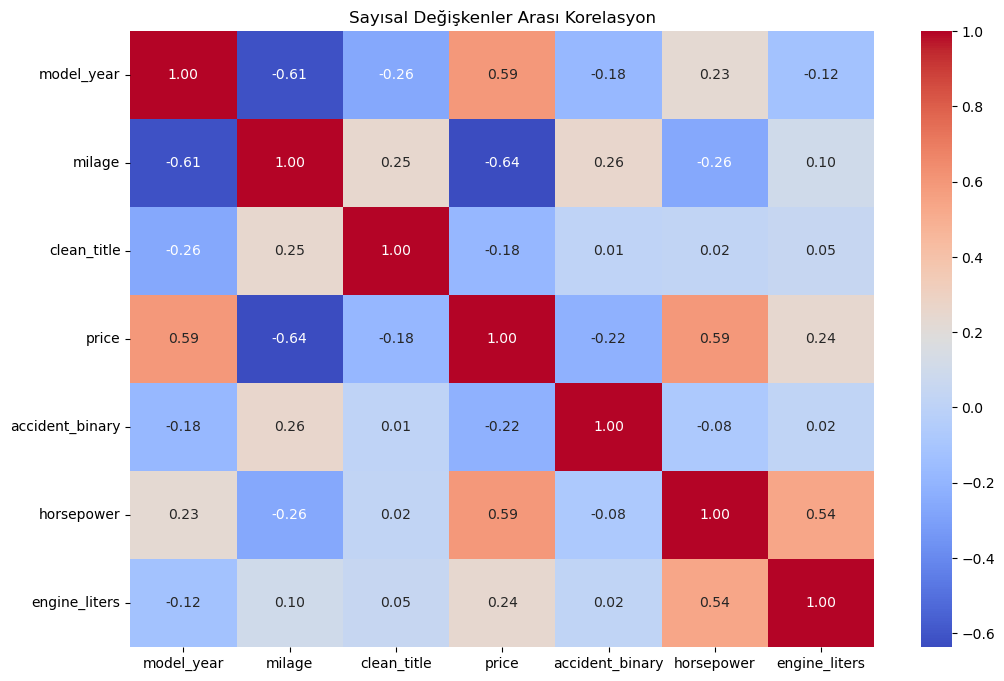

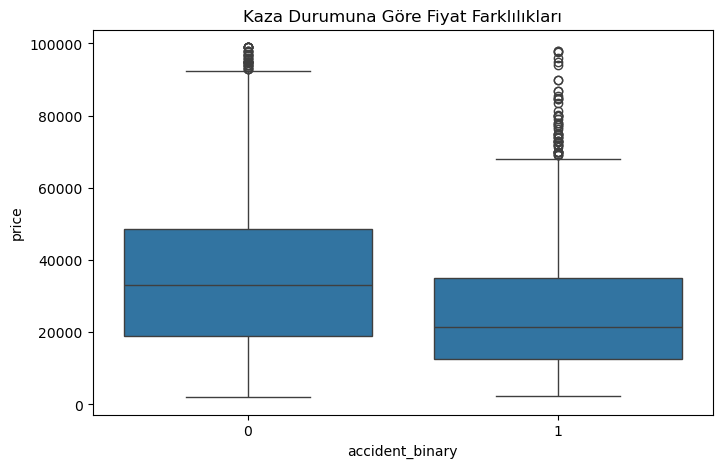

In [3]:
# 2.1. Hedef Değişken Analizi (Price)
plt.figure(figsize=(10, 6))
sns.histplot(df_cleaned['price'], kde=True, color='blue')
plt.title('Araç Fiyat Dağılımı')
plt.xlabel('Fiyat')
plt.show()

# 2.2. Korelasyon Matrisi
plt.figure(figsize=(12, 8))
numeric_df = df_cleaned.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Sayısal Değişkenler Arası Korelasyon')
plt.show()

# 2.3. Kaza Durumuna Göre Fiyat
plt.figure(figsize=(8, 5))
sns.boxplot(x='accident_binary', y='price', data=df_cleaned)
plt.title('Kaza Durumuna Göre Fiyat Farklılıkları')
plt.show()

## 3. Encoding, Ölçeklendirme ve PCA

In [4]:
# 3.1. Kategorik Değişken Dönüşümü (Label Encoding)
le = LabelEncoder()
categorical_cols = df_cleaned.select_dtypes(include=['object']).columns

df_encoded = df_cleaned.copy()
for col in categorical_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

# 3.2. Standardizasyon (Scaling)
scaler = StandardScaler()
X = df_encoded.drop('price', axis=1)
y = df_encoded['price']

X_scaled = scaler.fit_transform(X)

# CSV Kaydı (Scaled)
pd.DataFrame(X_scaled, columns=X.columns).to_csv('2_data_scaled.csv', index=False)

# 3.3. PCA (Principal Component Analysis)
# Varyansın %95'ini koruyacak şekilde boyut indirgeme
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

print(f"Orijinal Özellik Sayısı: {X.shape[1]}")
print(f"PCA Sonrası Özellik Sayısı: {X_pca.shape[1]}")

# CSV Kaydı (PCA)
pca_columns = [f'PC{i+1}' for i in range(X_pca.shape[1])]
df_pca = pd.DataFrame(X_pca, columns=pca_columns)
df_pca['target_price'] = y.values
df_pca.to_csv('3_data_pca_ready.csv', index=False)

Orijinal Özellik Sayısı: 12
PCA Sonrası Özellik Sayısı: 11


## 4. Makine Öğrenmesi Modelleri ve Eğitim

In [5]:
# Veriyi Eğitim ve Test Olarak Ayırma
X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=42)

# Modellerin Tanımlanması
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "SVR": SVR(),
    "KNN": KNeighborsRegressor()
}

# Sonuçları tutmak için sözlük
results = {}

print("Modeller eğitiliyor...\n")

for name, model in models.items():
    # Modeli eğit
    model.fit(X_train, y_train)
    
    # Tahmin yap
    y_pred = model.predict(X_test)
    
    # Metrikleri Hesapla
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    
    results[name] = {"R2 Score": r2, "RMSE": rmse, "MAE": mae}
    print(f"{name} -> R2: {r2:.4f}, RMSE: {rmse:.2f}")

Modeller eğitiliyor...

Linear Regression -> R2: 0.6337, RMSE: 12671.17
Decision Tree -> R2: 0.3958, RMSE: 16274.12
Random Forest -> R2: 0.7139, RMSE: 11198.65
SVR -> R2: -0.0271, RMSE: 21217.61
KNN -> R2: 0.6530, RMSE: 12333.40


### Hiperparametre Optimizasyonu (Random Forest)

In [6]:
print("\nRandom Forest için GridSearch yapılıyor...")
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=3, scoring='r2', n_jobs=-1)
rf_grid.fit(X_train, y_train)

print("En iyi parametreler:", rf_grid.best_params_)
print("En iyi R2 Skoru:", rf_grid.best_score_)

best_rf_model = rf_grid.best_estimator_


Random Forest için GridSearch yapılıyor...
En iyi parametreler: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}
En iyi R2 Skoru: 0.7327306673053376


## 5. Sonuçların Karşılaştırılması

,R2 Score,RMSE,MAE
Linear Regression,0.633693,12671.170970,9417.717927
Decision Tree,0.395764,16274.120561,11338.002656
Random Forest,0.713884,11198.645180,7863.239416
SVR,-0.027080,21217.606218,16518.694372
KNN,0.652962,12333.398651,8607.345817


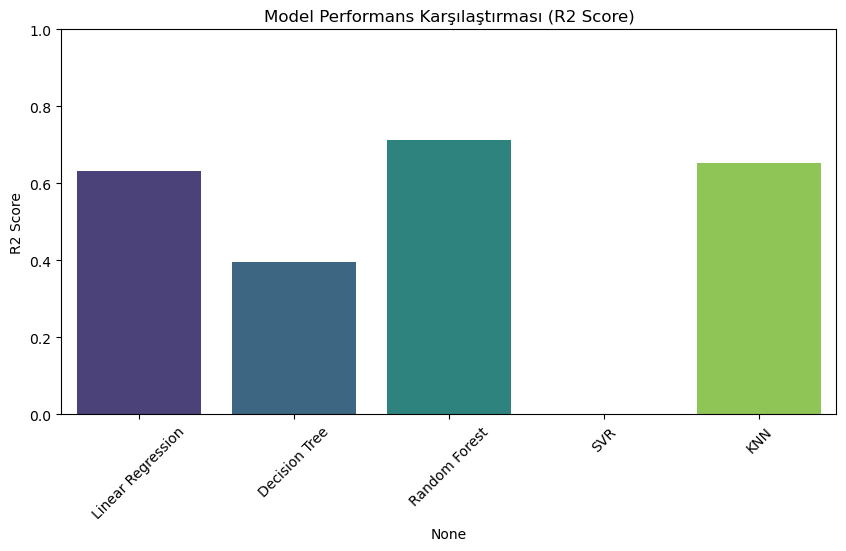

In [7]:
results_df = pd.DataFrame(results).T
display(results_df)

# Grafiksel Karşılaştırma
plt.figure(figsize=(10, 5))
sns.barplot(x=results_df.index, y=results_df['R2 Score'], palette="viridis")
plt.title('Model Performans Karşılaştırması (R2 Score)')
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.show()

# CSV Kaydı
results_df.to_csv('4_model_performance_results.csv')

## 6. Açıklanabilir Yapay Zeka (XAI - SHAP)
PCA sonrası özellikler anlamını yitirdiği için, açıklanabilirlik adına orijinal (sadece encode edilmiş) veri seti üzerinde küçük bir model eğitip SHAP değerlerini inceliyoruz.

SHAP Özellik Önem Grafiği:


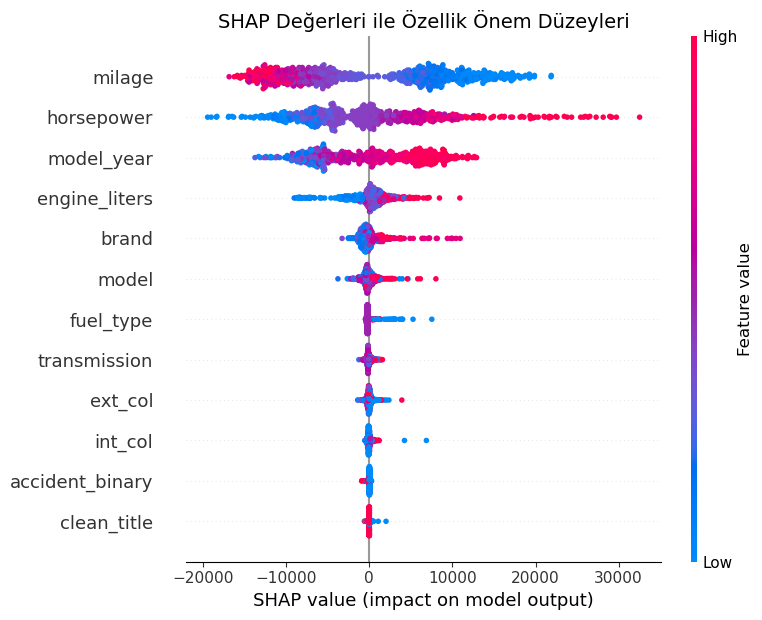

In [8]:
# XAI için Orijinal (PCA'sız ama encode edilmiş) veriyi kullanalım
X_train_orig, X_test_orig, y_train_orig, y_test_orig = train_test_split(X, y, test_size=0.2, random_state=42)

# Açıklanabilirlik için hızlı bir model kuralım
rf_explainer = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42)
rf_explainer.fit(X_train_orig, y_train_orig)

# SHAP Explainer oluşturma
explainer = shap.TreeExplainer(rf_explainer)
shap_values = explainer.shap_values(X_test_orig)

print("SHAP Özellik Önem Grafiği:")
plt.figure()
shap.summary_plot(shap_values, X_test_orig, show=False)
plt.title("SHAP Değerleri ile Özellik Önem Düzeyleri", fontsize=14)
plt.tight_layout()
plt.savefig('5_shap_summary_plot.png')
plt.show()